<a href="https://colab.research.google.com/github/theochi/MachineLearning/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task 1: Load Dataset**

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (VotingClassifier, BaggingClassifier,
                              RandomForestClassifier, AdaBoostClassifier)
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

column_names = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
                "insulin", "bmi", "diabetes_pedigree", "age", "outcome"]

df = pd.read_csv(URL, header=None, names=column_names)
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Shape: 768 rows x 9 columns


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


The code cells loads the dataset with columns that have also been given appropiate names.

**Task 2: Use Structural Inspection Methods**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pregnancies        768 non-null    int64  
 1   glucose            768 non-null    int64  
 2   blood_pressure     768 non-null    int64  
 3   skin_thickness     768 non-null    int64  
 4   insulin            768 non-null    int64  
 5   bmi                768 non-null    float64
 6   diabetes_pedigree  768 non-null    float64
 7   age                768 non-null    int64  
 8   outcome            768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


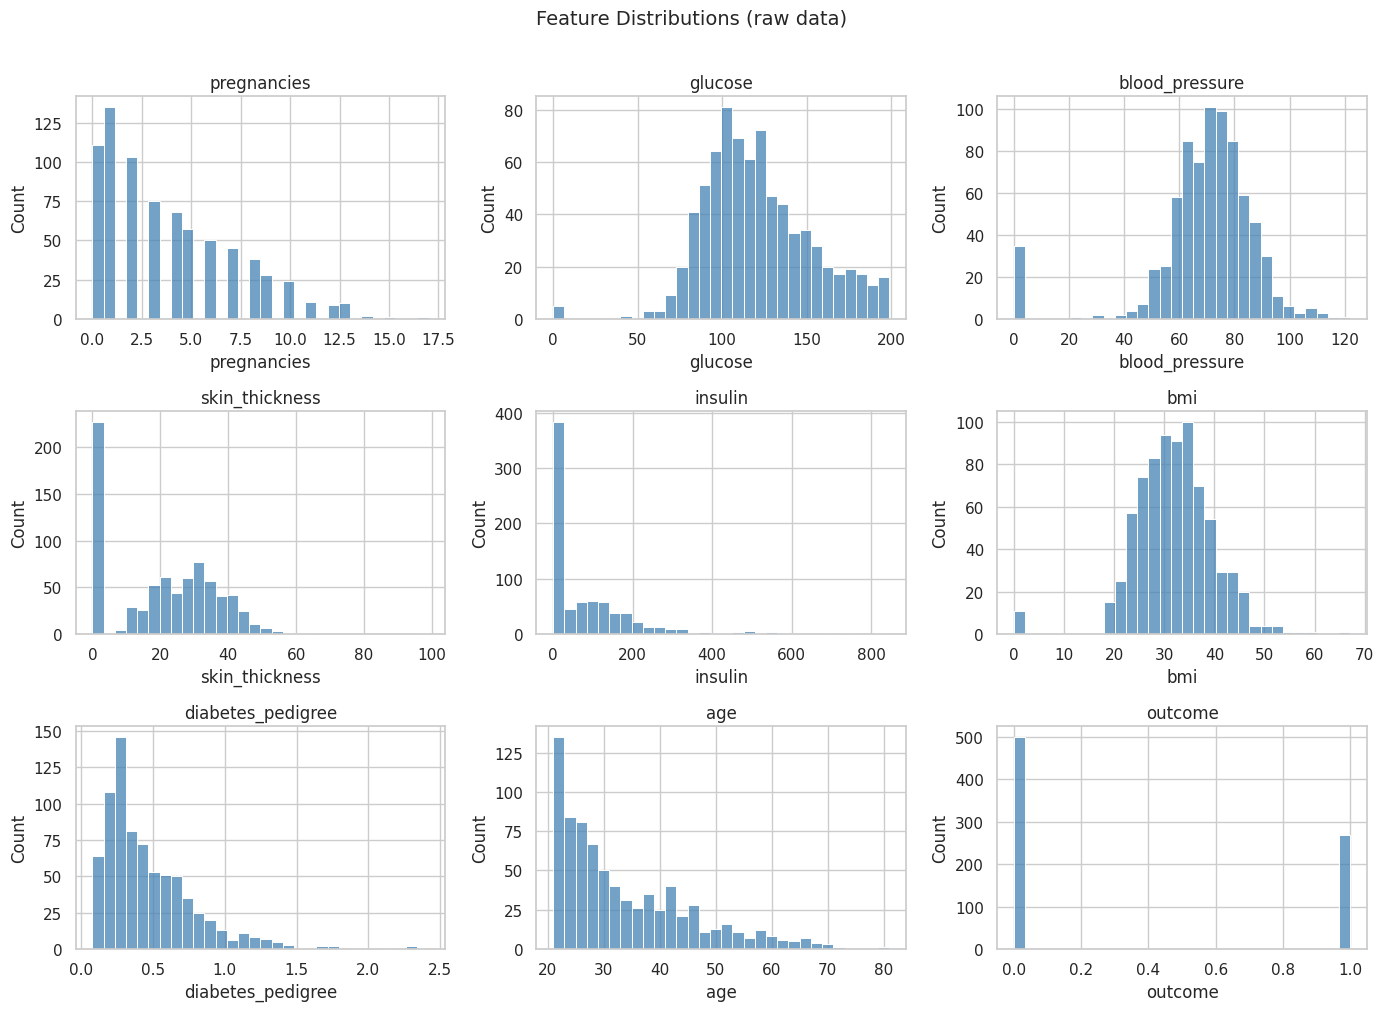

,count
outcome,
Non-diabetic (0),500
Diabetic (1),268


In [2]:
df.head(10)
df.info()
df.describe().T

zero_counts = (df.drop(columns="outcome") == 0).sum().to_frame("zero_count")
zero_counts["zero_pct"] = (zero_counts["zero_count"] / len(df) * 100).round(1)
zero_counts

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], bins=30, ax=ax, color="steelblue")
    ax.set_title(col)
plt.suptitle("Feature Distributions (raw data)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

df["outcome"].value_counts().rename({0: "Non-diabetic (0)", 1: "Diabetic (1)"})

This code cell inspects the dataset with: head, info and describe.

**Task 3: Quantify and Handle Values**

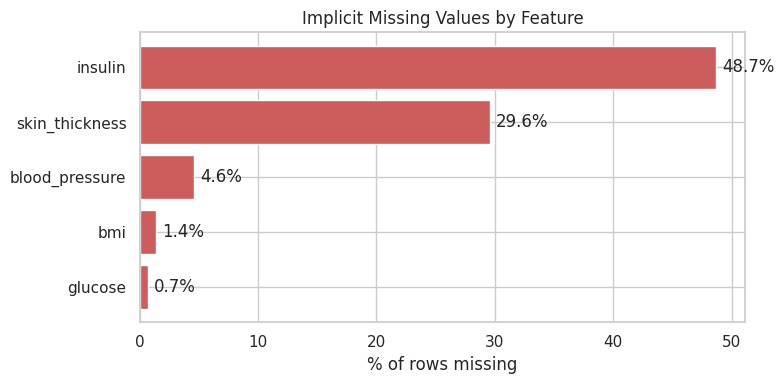

Medians learned from training data:
glucose           117.0
blood_pressure     72.0
skin_thickness     29.0
insulin           125.0
bmi                32.4
dtype: float64

Missing values remaining -> train: 0 | test: 0


In [3]:
implicit_missing_cols = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]

df_clean = df.copy()
df_clean[implicit_missing_cols] = df_clean[implicit_missing_cols].replace(0, np.nan)

missing_summary = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_pct": (df_clean.isna().mean() * 100).round(1)
})
missing_summary[missing_summary["missing_count"] > 0]

ms = missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_pct")
plt.figure(figsize=(8, 4))
plt.barh(ms.index, ms["missing_pct"], color="indianred")
for i, v in enumerate(ms["missing_pct"]):
    plt.text(v + 0.5, i, f"{v}%", va="center")
plt.xlabel("% of rows missing")
plt.title("Implicit Missing Values by Feature")
plt.tight_layout()
plt.show()

X = df_clean.drop(columns="outcome")
y = df_clean["outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[implicit_missing_cols])

print("Medians learned from training data:")
print(pd.Series(imputer.statistics_, index=implicit_missing_cols).round(2))

X_train_imp = X_train.copy()
X_test_imp = X_test.copy()
X_train_imp[implicit_missing_cols] = imputer.transform(X_train[implicit_missing_cols])
X_test_imp[implicit_missing_cols] = imputer.transform(X_test[implicit_missing_cols])

print("\nMissing values remaining -> train:", int(X_train_imp.isna().sum().sum()),
      "| test:", int(X_test_imp.isna().sum().sum()))

This code cell turns impossible zeros in the different categories into missing values. It then counts how many each category has and it has been plotted onto a graph.

**Task 4: Build Scikit-Learn ColumnTransformer and Pipeline**

In [4]:
other_numeric_cols = ["pregnancies", "diabetes_pedigree", "age"]

impute_and_scale = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("impute_scale", impute_and_scale, implicit_missing_cols),
    ("scale", StandardScaler(), other_numeric_cols)
])

def make_pipeline(model):
    """Attach the shared preprocessor to any classifier."""
    return Pipeline(steps=[("preprocess", preprocessor), ("model", model)])

X_train_transformed = preprocessor.fit_transform(X_train)
print("Transformed training shape:", X_train_transformed.shape)
print("Feature order:", list(preprocessor.get_feature_names_out()))
pd.DataFrame(X_train_transformed, columns=preprocessor.get_feature_names_out()) \
  .describe().loc[["mean", "std"]].round(3)

Transformed training shape: (614, 8)
Feature order: ['impute_scale__glucose', 'impute_scale__blood_pressure', 'impute_scale__skin_thickness', 'impute_scale__insulin', 'impute_scale__bmi', 'scale__pregnancies', 'scale__diabetes_pedigree', 'scale__age']


,impute_scale__glucose,impute_scale__blood_pressure,impute_scale__skin_thickness,impute_scale__insulin,impute_scale__bmi,scale__pregnancies,scale__diabetes_pedigree,scale__age
mean,-0.000,0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001




*   ColumnTransformer imputes and scales five columns. Pipeline wraps each model with preprocessing.




**Task 5: Train HVC & SVC**

Hard Voting test accuracy: 0.7273
Soft Voting test accuracy: 0.7273
=== Hard Voting Classifier ===
                  precision    recall  f1-score   support

Non-diabetic (0)       0.77      0.82      0.80       100
    Diabetic (1)       0.62      0.56      0.59        54

        accuracy                           0.73       154
       macro avg       0.70      0.69      0.69       154
    weighted avg       0.72      0.73      0.72       154

=== Soft Voting Classifier ===
                  precision    recall  f1-score   support

Non-diabetic (0)       0.76      0.85      0.80       100
    Diabetic (1)       0.64      0.50      0.56        54

        accuracy                           0.73       154
       macro avg       0.70      0.68      0.68       154
    weighted avg       0.72      0.73      0.72       154



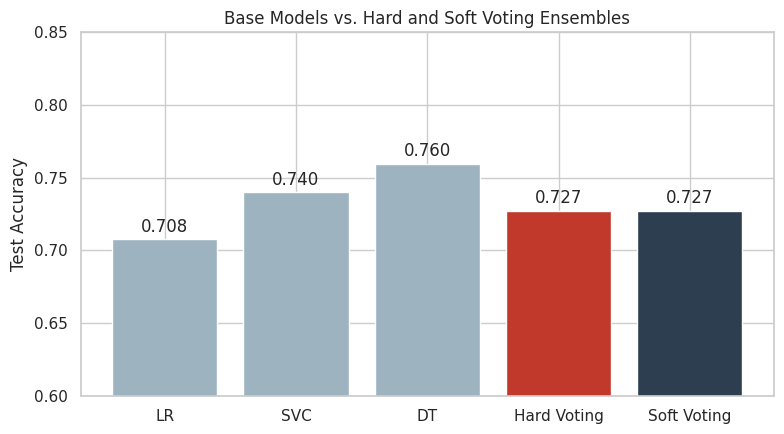

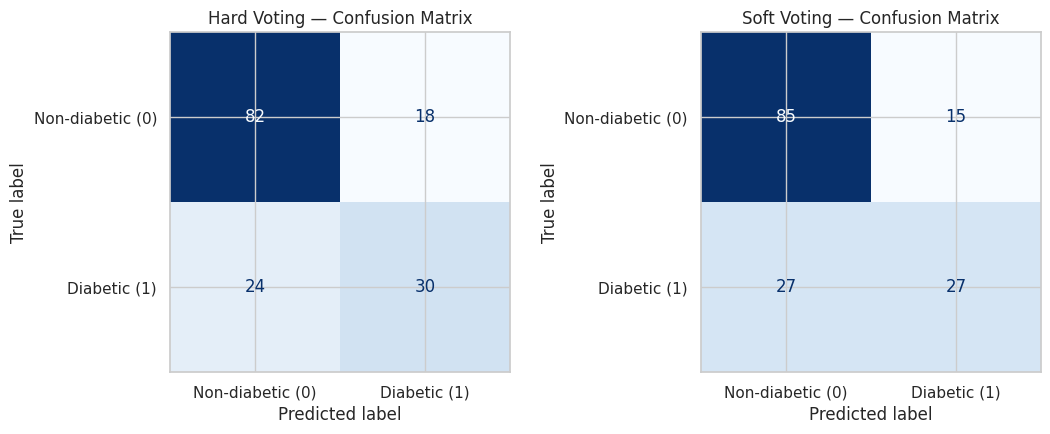

In [5]:
log_clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
svc_clf = SVC(probability=True, random_state=RANDOM_STATE)
dt_clf = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)

base_estimators = [("lr", log_clf), ("svc", svc_clf), ("dt", dt_clf)]

hard_voting = make_pipeline(VotingClassifier(estimators=base_estimators, voting="hard"))
soft_voting = make_pipeline(VotingClassifier(estimators=base_estimators, voting="soft"))

hard_voting.fit(X_train, y_train)
soft_voting.fit(X_train, y_train)

y_pred_hard = hard_voting.predict(X_test)
y_pred_soft = soft_voting.predict(X_test)

print(f"Hard Voting test accuracy: {accuracy_score(y_test, y_pred_hard):.4f}")
print(f"Soft Voting test accuracy: {accuracy_score(y_test, y_pred_soft):.4f}")

target_names = ["Non-diabetic (0)", "Diabetic (1)"]
print("=== Hard Voting Classifier ===")
print(classification_report(y_test, y_pred_hard, target_names=target_names))
print("=== Soft Voting Classifier ===")
print(classification_report(y_test, y_pred_soft, target_names=target_names))

voting_results = {}
for name, clf in base_estimators:
    pipe = make_pipeline(clf).fit(X_train, y_train)
    voting_results[name.upper()] = accuracy_score(y_test, pipe.predict(X_test))
voting_results["Hard Voting"] = accuracy_score(y_test, y_pred_hard)
voting_results["Soft Voting"] = accuracy_score(y_test, y_pred_soft)

colors = ["#9db4c0"] * 3 + ["#c0392b", "#2c3e50"]
plt.figure(figsize=(8, 4.5))
bars = plt.bar(voting_results.keys(), voting_results.values(), color=colors)
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005,
             f"{b.get_height():.3f}", ha="center")
plt.ylim(0.6, 0.85)
plt.ylabel("Test Accuracy")
plt.title("Base Models vs. Hard and Soft Voting Ensembles")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, preds) in zip(axes, [("Hard Voting", y_pred_hard), ("Soft Voting", y_pred_soft)]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=target_names,
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{title} — Confusion Matrix")
plt.tight_layout()
plt.show()

This code cell shows hard and soft voting classifiers and how they had a test accuracy of 72.7%. One overall chart was created to compare test accuracy of LR, SVC, DT, Hard and Soft voting. There are 2 other charts one for hard and soft voting.

**Task 6: Train Bagging Classifier using Decision Tree Base Estimators**

Bagging training accuracy : 1.0000
Bagging OOB score         : 0.7573
Bagging test accuracy     : 0.7403
Gap (OOB - test)          : +0.0171

                  precision    recall  f1-score   support

Non-diabetic (0)       0.77      0.85      0.81       100
    Diabetic (1)       0.66      0.54      0.59        54

        accuracy                           0.74       154
       macro avg       0.72      0.69      0.70       154
    weighted avg       0.73      0.74      0.73       154



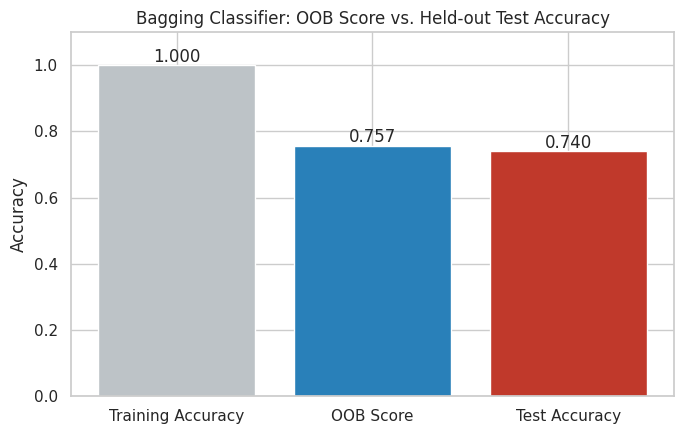

In [6]:
bagging = make_pipeline(BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=500,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE
))
bagging.fit(X_train, y_train)

bag_oob = bagging.named_steps["model"].oob_score_
bag_train = accuracy_score(y_train, bagging.predict(X_train))
bag_test = accuracy_score(y_test, bagging.predict(X_test))

print(f"Bagging training accuracy : {bag_train:.4f}")
print(f"Bagging OOB score         : {bag_oob:.4f}")
print(f"Bagging test accuracy     : {bag_test:.4f}")
print(f"Gap (OOB - test)          : {bag_oob - bag_test:+.4f}")
print()
print(classification_report(y_test, bagging.predict(X_test), target_names=target_names))

labels = ["Training Accuracy", "OOB Score", "Test Accuracy"]
values = [bag_train, bag_oob, bag_test]

plt.figure(figsize=(7, 4.5))
bars = plt.bar(labels, values, color=["#bdc3c7", "#2980b9", "#c0392b"])
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01,
             f"{b.get_height():.3f}", ha="center")
plt.ylim(0, 1.1)
plt.ylabel("Accuracy")
plt.title("Bagging Classifier: OOB Score vs. Held-out Test Accuracy")
plt.tight_layout()
plt.show()

This code cell performs the bagging and bootstrap sampling. It shows the comparison between OOB score against test accuracy and the results have been plotted on a graph.

**Task 7: Train a RFC**

Random Forest training accuracy: 1.0000
Random Forest test accuracy    : 0.7338

                  precision    recall  f1-score   support

Non-diabetic (0)       0.78      0.83      0.80       100
    Diabetic (1)       0.64      0.56      0.59        54

        accuracy                           0.73       154
       macro avg       0.71      0.69      0.70       154
    weighted avg       0.73      0.73      0.73       154



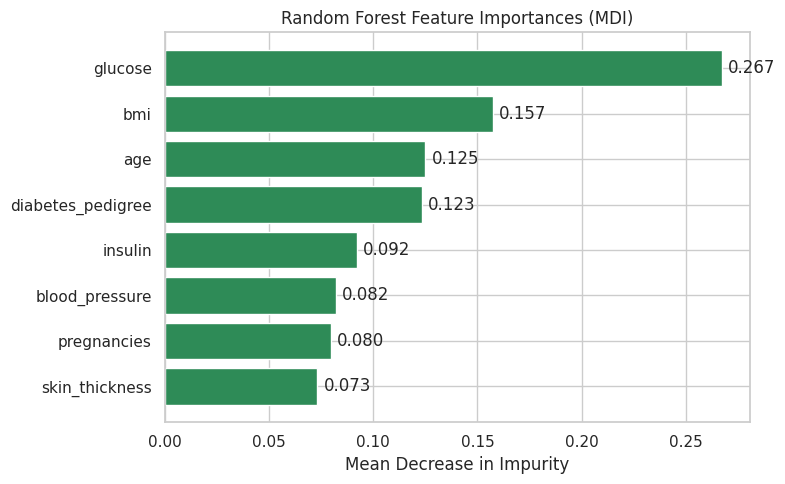

In [7]:
rf = make_pipeline(RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    bootstrap=True,
    n_jobs=-1,
    random_state=RANDOM_STATE
))
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print(f"Random Forest training accuracy: {accuracy_score(y_train, rf.predict(X_train)):.4f}")
print(f"Random Forest test accuracy    : {accuracy_score(y_test, y_pred_rf):.4f}")
print()
print(classification_report(y_test, y_pred_rf, target_names=target_names))

feature_names = [n.split("__")[1] for n in rf.named_steps["preprocess"].get_feature_names_out()]
importances = pd.Series(rf.named_steps["model"].feature_importances_,
                        index=feature_names).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(importances.index, importances.values, color="seagreen")
for i, v in enumerate(importances.values):
    plt.text(v + 0.003, i, f"{v:.3f}", va="center")
plt.xlabel("Mean Decrease in Impurity")
plt.title("Random Forest Feature Importances (MDI)")
plt.tight_layout()
plt.show()

This code cells train a random forest classifier. A horizontal bar plot has also been made.

**Task 8: Train an AdaBoost Classifier**

AdaBoost training accuracy: 0.8094
AdaBoost test accuracy    : 0.7597

                  precision    recall  f1-score   support

Non-diabetic (0)       0.79      0.86      0.82       100
    Diabetic (1)       0.69      0.57      0.63        54

        accuracy                           0.76       154
       macro avg       0.74      0.72      0.72       154
    weighted avg       0.75      0.76      0.75       154



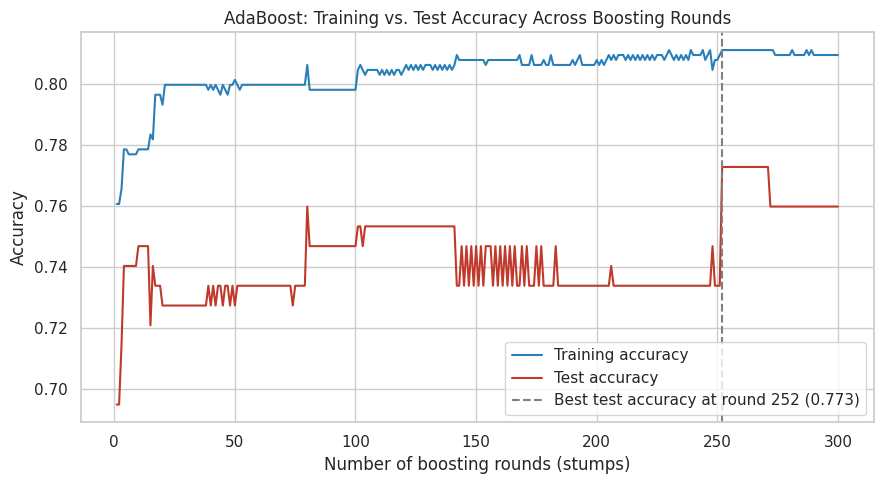

Final train-test gap: +0.0497


In [8]:
ada = make_pipeline(AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),   # decision stump
    n_estimators=300,
    learning_rate=0.5,
    random_state=RANDOM_STATE
))
ada.fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)

print(f"AdaBoost training accuracy: {accuracy_score(y_train, ada.predict(X_train)):.4f}")
print(f"AdaBoost test accuracy    : {accuracy_score(y_test, y_pred_ada):.4f}")
print()
print(classification_report(y_test, y_pred_ada, target_names=target_names))

ada_model = ada.named_steps["model"]
Xtr_t = ada.named_steps["preprocess"].transform(X_train)
Xte_t = ada.named_steps["preprocess"].transform(X_test)

train_scores = [accuracy_score(y_train, p) for p in ada_model.staged_predict(Xtr_t)]
test_scores = [accuracy_score(y_test, p) for p in ada_model.staged_predict(Xte_t)]
rounds = np.arange(1, len(train_scores) + 1)
best_round = int(np.argmax(test_scores)) + 1

plt.figure(figsize=(9, 5))
plt.plot(rounds, train_scores, label="Training accuracy", color="#2980b9")
plt.plot(rounds, test_scores, label="Test accuracy", color="#c0392b")
plt.axvline(best_round, ls="--", color="gray",
            label=f"Best test accuracy at round {best_round} ({max(test_scores):.3f})")
plt.xlabel("Number of boosting rounds (stumps)")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Training vs. Test Accuracy Across Boosting Rounds")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Final train-test gap: {train_scores[-1] - test_scores[-1]:+.4f}")

This code cell trains an AdaBoost classifier with decision stamps. The results were put onto a line chart.